In [2]:
## Python Stuff
import os
import sys
import numpy as np
from array import array
import copy
import time
import matplotlib.pyplot as plt
import matplotlib
import json5 as json

import uproot

os.environ.get("ROOTSYS")

'/Users/austindestcroix/packages/root_py311_v6_26.10/myInstall_p311'

In [3]:
## ROOT stuff
import ROOT
from ROOT import TFile, TTree, TCanvas
from ROOT import TH1F, TH2F
import ctypes
import copy

ROOT.gStyle.SetCanvasDefW(600)
ROOT.gStyle.SetCanvasDefH(500)

# ROOT.gErrorIgnoreLevel = ROOT.kFatal
ROOT.gROOT.SetBatch(False)
# ROOT.enableJSVis()
# ROOT.disableJSVis()

## Atown's stuff
sys.path.append("..")
from globalsC2 import *
from helpers.anaStructs import * # includes SORTING class/namespace
from helpers.getSPE import *
import helpers.graphBuilders as GB

import MakeSpectra as MS
print(COMP2PATH)

Welcome to JupyROOT 6.27/01
CF4HOME: /Users/austindestcroix/Desktop/school_holders/projects/sbc/CF4
COMP2PATH: /Users/austindestcroix/Desktop/school_holders/projects/sbc/CF4/comp2
/Users/austindestcroix/Desktop/school_holders/projects/sbc/CF4/comp2


---
### Cs - LP background runs

In [4]:
## loading run lists
rid_Cs_bkg = np.loadtxt(os.path.join(COMP2PATH, "runLists/CsLists/LPfilter_april_48V_background.txt"), dtype=str).tolist()
print(f"Loaded {len(rid_Cs_bkg)} runs for Cs background.")

runId, speValues, rc_Cs_LP_bkg, tFiles = MS.ExtractSPE(fileConfig=os.path.join(COMP2PATH, "pyScripts/files.json"), anaConfig=os.path.join(COMP2PATH, "pyScripts/speAnalysis.json"), argRunList=rid_Cs_bkg)
print(speValues[0][0].spe)

for rc in rc_Cs_LP_bkg:
  rc.print()

Loaded 7 runs for Cs background.
150.58693264394145

runID: 202204111213
Nevents: 14266.00,   time: 7.24 min
average Rate: 32.83 Hz
chID:0: spe = 150.59 +/- 0.42     maxChi2 = 11.68
chID:1: spe = 156.79 +/- 0.62     maxChi2 = 12.13
chID:2: spe = 157.07 +/- 0.50     maxChi2 = 6.28

runID: 202204111229
Nevents: 20738.00,   time: 9.70 min
average Rate: 35.64 Hz
chID:0: spe = 150.30 +/- 0.36     maxChi2 = 18.77
chID:1: spe = 157.36 +/- 0.48     maxChi2 = 9.93
chID:2: spe = 157.42 +/- 0.42     maxChi2 = 15.88

runID: 202204111247
Nevents: 12420.00,   time: 5.30 min
average Rate: 39.02 Hz
chID:0: spe = 150.38 +/- 0.50     maxChi2 = 18.98
chID:1: spe = 157.29 +/- 0.62     maxChi2 = 8.33
chID:2: spe = 156.41 +/- 0.56     maxChi2 = 41.43

runID: 202204111323
Nevents: 27391.00,   time: 12.92 min
average Rate: 35.33 Hz
chID:0: spe = 149.90 +/- 0.31     maxChi2 = 34.92
chID:1: spe = 156.47 +/- 0.44     maxChi2 = 13.30
chID:2: spe = 155.89 +/- 0.36     maxChi2 = 64.63

runID: 202204111434
Nevents: 

2025-12-11 15:01:15.441 Python[38546:87493370] WARNING: Secure coding is not enabled for restorable state! Enable secure coding by implementing NSApplicationDelegate.applicationSupportsSecureRestorableState: and returning YES.


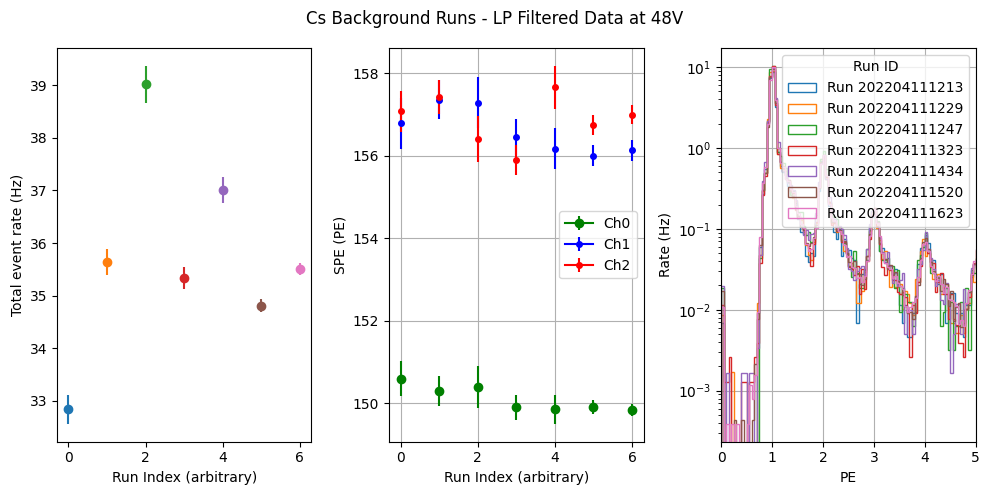

In [5]:
## plotting SPE vs background run
fig, (axrate, axspe, axbkg) = plt.subplots(1, 3, figsize=(10, 5))

anaCfg = MS.AnalysisConfig(os.path.join(COMP2PATH, "pyScripts/analysis.json"))

chCols = ["green", "blue", "red"]
for i, rc in enumerate(rc_Cs_LP_bkg):
  # rc.mpl_errorbar(axbkg, rate = True, label=f"Run {rc.id}", fmt='o', color=f"C{i}") 
  
  # axbkg.hist(x = rc.mBinX, bins = rc.mBin_edges, weights=rc.mBin_rawCounts)
  rc.mpl_hist(axbkg, rate=True, color=f"C{i}", label=f"Run {rc.id}", histtype='step')
  
  axrate.errorbar(i, rc.GetRate(), yerr=rc.GetRateError(), marker='o', color=f"C{i}", label=f"Run {rc.id}")
  for ich in range(anaCfg.nChan):
    chan = rc.GetChan(ich)
    label = None
    if i == 0:
      label = f"Ch{ich}"
    msize = 6 if ich == 0 else 4
    axspe.errorbar(i, chan.mSpe.spe, yerr=chan.mSpe.espe, marker = "o", markersize=msize, color=chCols[ich], label=label)

axrate.set_ylabel("Total event rate (Hz)")
axrate.set_xlabel("Run Index (arbitrary)")

axspe.legend()
axspe.set_ylabel("SPE (PE)")
axspe.set_xlabel("Run Index (arbitrary)")
axspe.grid()

axbkg.legend(title="Run ID")
axbkg.set_xlabel("PE")
axbkg.set_ylabel("Rate (Hz)")
axbkg.set_xlim(0, 5)
axbkg.set_yscale('log')
# axbkg.vlines((1, 2), ymin=1e-4, ymax=1e2, colors='gray', linestyles='dashed')
axbkg.grid()

fig.suptitle("Cs Background Runs - LP Filtered Data at 48V")
plt.tight_layout()
plt.show()

---
### Co - LP background runs

In [6]:
## loading run lists
rid_Co_bkg = np.loadtxt(os.path.join(COMP2PATH, "runLists/CoLists/LPfilter_april_48V_fineCol_bkg.txt"), dtype=str).tolist()
print(f"Loaded {len(rid_Co_bkg)} runs for Co background.")

runId, speValues, rc_Co_LP_bkg, tFiles = MS.ExtractSPE(fileConfig=os.path.join(COMP2PATH, "pyScripts/files.json"), anaConfig=os.path.join(COMP2PATH, "pyScripts/speAnalysis.json"), argRunList=rid_Co_bkg)

Loaded 7 runs for Co background.


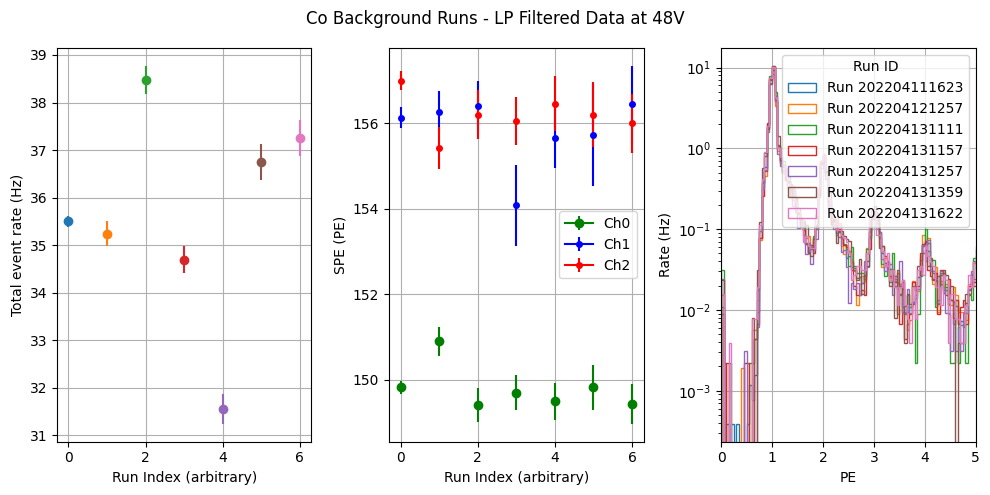

In [7]:
## plotting SPE vs background run
fig, (axrate, axspe, axbkg) = plt.subplots(1, 3, figsize=(10, 5))
anaCfg = MS.AnalysisConfig(os.path.join(COMP2PATH, "pyScripts/analysis.json"))

chCols = ["green", "blue", "red"]
for i, rc in enumerate(rc_Co_LP_bkg):
  
  axrate.errorbar(i, rc.GetRate(), yerr=rc.GetRateError(), marker='o', color=f"C{i}", label=f"Run {rc.id}")
  rc.mpl_hist(axbkg, rate=True, color=f"C{i}", label=f"Run {rc.id}", histtype='step')
  
  for ich in range(anaCfg.nChan):
    chan = rc.GetChan(ich)
    label = None
    if i == 0:
      label = f"Ch{ich}"
    msize = 6 if ich == 0 else 4
    axspe.errorbar(i, chan.mSpe.spe, yerr=chan.mSpe.espe, marker = "o", markersize=msize, color=chCols[ich], label=label)

axbkg.set_xlim(0, 10)
axbkg.set_yscale('log')

# axbkg.vlines((1, 2), ymin=1e-4, ymax=1e2, colors='gray', linestyles='dashed')

axrate.set_xlabel("Run Index (arbitrary)")
axrate.set_ylabel("Total event rate (Hz)")
axrate.grid()

axspe.legend()
axspe.set_ylabel("SPE (PE)")
axspe.set_xlabel("Run Index (arbitrary)")
axspe.grid()

axbkg.legend(title="Run ID")
axbkg.set_xlabel("PE")
axbkg.set_ylabel("Rate (Hz)")
axbkg.set_xlim(0, 5)
axbkg.grid()

fig.suptitle("Co Background Runs - LP Filtered Data at 48V")
plt.tight_layout()
plt.show()

---
### rebinning all LP bkg spectra

In [8]:
MS.RebinRCObjects(rcList = rc_Co_LP_bkg + rc_Cs_LP_bkg, anaConfig=os.path.join(COMP2PATH, "pyScripts/analysis.json"))

---
### Averaging April (LP) backgrounds

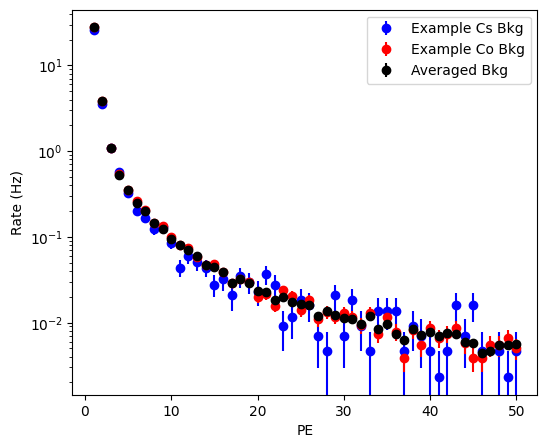

In [9]:
fig, axAvg = plt.subplots(1, 1, figsize=(6, 5))

rc_Cs_LP_bkg[0].mpl_errorbar(axAvg, rate = True, label="Example Cs Bkg", fmt='o', color='blue')
rc_Co_LP_bkg[0].mpl_errorbar(axAvg, rate = True, label="Example Co Bkg", fmt='o', color='red')

rcAvgBkg = RunClass.CombineRCs(name="avg_bkp_lp", rcList=rc_Cs_LP_bkg + rc_Co_LP_bkg)
rcAvgBkg.mpl_errorbar(axAvg, rate = True, label="Averaged Bkg", fmt='o', color='black')

axAvg.set_yscale('log')
axAvg.set_xlabel("PE")
axAvg.set_ylabel("Rate (Hz)")
axAvg.legend()

---
### Co LP source data

In [10]:
## loading run lists
rid_Co, heights_Co = np.loadtxt(os.path.join(COMP2PATH, "runLists/CoLists/LPfilter_april_48V_fineCol.txt"), dtype=str, delimiter=",", unpack=True)

runId, speValues, rc_Co_LP, tFiles = MS.ExtractSPE(argRunList=rid_Co, fileConfig=os.path.join(COMP2PATH, "pyScripts/files.json"), anaConfig=os.path.join(COMP2PATH, "pyScripts/speAnalysis.json"))

for rc, h in zip(rc_Co_LP, heights_Co):
  rc.mHeight = float(h)
  rc.print()
# print(f"Loaded {len(rid_Co_bkg)} runs for Co background.")


runID: 202204131513
Nevents: 167817.00,   time: 68.29 min
average Rate: 40.96 Hz
height = 26.00
chID:0: spe = 149.29 +/- 0.11     maxChi2 = 153.95
chID:1: spe = 156.25 +/- 0.24     maxChi2 = 66.88
chID:2: spe = 156.40 +/- 0.18     maxChi2 = 186.39

runID: 202204131317
Nevents: 111250.00,   time: 41.72 min
average Rate: 44.44 Hz
height = 28.50
chID:0: spe = 149.58 +/- 0.14     maxChi2 = 86.13
chID:1: spe = 155.98 +/- 0.28     maxChi2 = 89.56
chID:2: spe = 156.52 +/- 0.22     maxChi2 = 105.61

runID: 202204131122
Nevents: 130985.00,   time: 34.32 min
average Rate: 63.60 Hz
height = 30.50
chID:0: spe = 149.74 +/- 0.11     maxChi2 = 111.77
chID:1: spe = 155.89 +/- 0.23     maxChi2 = 36.83
chID:2: spe = 156.46 +/- 0.20     maxChi2 = 127.66


---
### Cs LP source data

In [11]:
## loading run lists
rid_Cs, heights_Cs = np.loadtxt(os.path.join(COMP2PATH, "runLists/CsLists/LPfilter_april_48V.txt"), dtype=str, delimiter=",", unpack=True)

runId, speValues, rc_Cs_LP, tFiles = MS.ExtractSPE(argRunList=rid_Cs, fileConfig=os.path.join(COMP2PATH, "pyScripts/files.json"), anaConfig=os.path.join(COMP2PATH, "pyScripts/speAnalysis.json"))

for rc, h in zip(rc_Cs_LP, heights_Cs):
  rc.mHeight = float(h)
  rc.print()


runID: 202204111600
Nevents: 52882.00,   time: 22.40 min
average Rate: 39.35 Hz
height = 26.00
chID:0: spe = 149.94 +/- 0.19     maxChi2 = 21.95
chID:1: spe = 156.06 +/- 0.32     maxChi2 = 33.28
chID:2: spe = 156.59 +/- 0.29     maxChi2 = 12.57

runID: 202204111454
Nevents: 60745.00,   time: 24.90 min
average Rate: 40.65 Hz
height = 28.50
chID:0: spe = 149.97 +/- 0.17     maxChi2 = 36.28
chID:1: spe = 156.03 +/- 0.28     maxChi2 = 68.59
chID:2: spe = 156.48 +/- 0.27     maxChi2 = 6.93

runID: 202204111423
Nevents: 29620.00,   time: 11.25 min
average Rate: 43.90 Hz
height = 30.50
chID:0: spe = 150.18 +/- 0.26     maxChi2 = 26.77
chID:1: spe = 156.40 +/- 0.38     maxChi2 = 10.19
chID:2: spe = 156.84 +/- 0.36     maxChi2 = 56.25

runID: 202204121321
Nevents: 51297.00,   time: 22.52 min
average Rate: 37.96 Hz
height = 32.00
chID:0: spe = 150.30 +/- 0.21     maxChi2 = 36.29
chID:1: spe = 156.19 +/- 0.30     maxChi2 = 34.98
chID:2: spe = 156.66 +/- 0.25     maxChi2 = 126.90


---
### rebinning source spectra

In [12]:
MS.RebinRCObjects(rcList = rc_Co_LP + rc_Cs_LP, anaConfig=os.path.join(COMP2PATH, "pyScripts/analysis.json"))

---
### Background Subtraction and Error Propagation
To subtract a scaled background from your data and properly propagate uncertainties, use the following formulas:

$$
N_{\text{signal}} = N_{\text{data}} - R_{\text{bkg}} \times t
$$

where:

- $N_{\text{data}}$ is the observed number of counts in the data run.
- $R_{\text{bkg}}$ is the background rate (Hz or counts/s).
- $t$ is the run time (s).

The total uncertainty on the expected background counts is:

$$
\sigma_{\text{Bkg}} = \sqrt{(t \cdot \sigma_{R_{\text{bkg}}})^2 + R_{\text{bkg}} \cdot t}
$$

where:

- $\sigma_{R_{\text{bkg}}}$ is the uncertainty on the background rate.
- $R_{\text{bkg}} \cdot t$ is the Poisson variance for the expected background counts (from counting statistics).

The total uncertainty on the background-subtracted signal is:

$$
\sigma_{\text{signal}} = \sqrt{N_{\text{data}} + \sigma_{\text{Bkg}}^2}
$$
This approach accounts for both the statistical uncertainty in the data and the propagated uncertainty from the scaled background.

---
### Co bkg subtraction

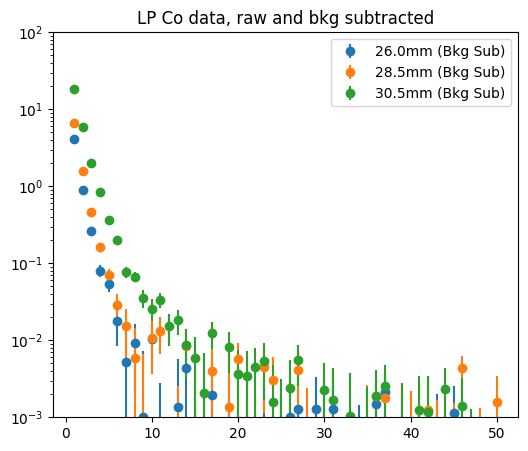

In [13]:
## uncorrected signal spectra
fig, axsig = plt.subplots(1, 1, figsize=(6, 5))

for rc in rc_Co_LP:
  # rc.BkgCorrected_spectrum(bkgRC=rcAvgBkg)
  # rc.mpl_errorbar(axsig, rate = True, bkgCorrected=False, label=f"{rc.mHeight}mm", marker='v', linestyle = "None")
  
  rc.BackgroundSubtraction(rcbkg=rcAvgBkg)
  rc.mpl_errorbar(axsig, rate = True, bkgCorrected=True, label=f"{rc.mHeight}mm (Bkg Sub)", marker = "o", linestyle = "None")

axsig.set_yscale('log')
axsig.set_ylim(1e-3, 1e2)
axsig.set_title("LP Co data, raw and bkg subtracted")
axsig.legend()
plt.show()

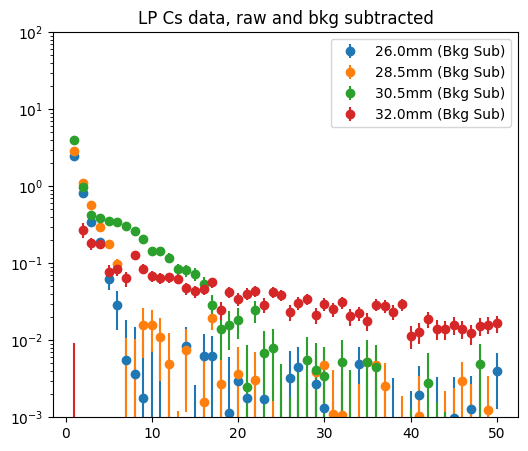

In [14]:
## uncorrected signal spectra
fig, axsig = plt.subplots(1, 1, figsize=(6, 5))
for rc in rc_Cs_LP:
  rc.BackgroundSubtraction(rcbkg=rcAvgBkg)
  rc.mpl_errorbar(axsig, rate = True, bkgCorrected=True, label=f"{rc.mHeight}mm (Bkg Sub)", marker = "o", linestyle = "None")

axsig.set_yscale('log')
axsig.set_ylim(1e-3, 1e2)
axsig.set_title("LP Cs data, raw and bkg subtracted")
axsig.legend()
plt.show()